# Lecture 23 — Differentiable and compiled Python with JAX

In L22 we added a 3 Hz ripple to a 1 Hz wave. Suppose we know both frequencies and have the same 32 readings. Can we recover the amplitude of the ripple?

[JAX](<https://en.wikipedia.org/wiki/JAX_(software)>) is an open-source Python library for numerical calculations on arrays. Its `jax.numpy` module provides familiar NumPy operations. In the first cell we import it as `jnp` and generate the waves with `jnp.cos`, just as we used `np.cos` in L22.

With [**`jax.jit`**](https://docs.jax.dev/en/latest/_autosummary/jax.jit.html), JAX compiles our wave prediction on its first call. We can reuse the compiled code to try another amplitude. We score each prediction against all 32 readings. [**`jax.grad`**](https://docs.jax.dev/en/latest/_autosummary/jax.grad.html) uses automatic differentiation (autodiff) to compute the slope of that score at `a = 0.2`. With automatic vectorisation, [**`jax.vmap`**](https://docs.jax.dev/en/latest/_autosummary/jax.vmap.html) applies the same function to a batch of amplitudes. Each amplitude gets its own score against the same readings.

Starred sections and subsections are outside the written exam. Run the setup cells in order since later examples use the same waves.

The examples run on a CPU with JAX, NumPy and Matplotlib. We generate the readings with a ripple amplitude of 0.5 so we can check the fit.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = {'retina', 'pdf'}
from statistics import median
from time import perf_counter

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 160  # Retina output is rendered at 320 dpi.
t = jnp.arange(32, dtype=jnp.float32) / 16  # 16 readings per second
slow = jnp.cos(2 * jnp.pi * t)
ripple = jnp.cos(2 * jnp.pi * 3 * t)
observed = slow + 0.5 * ripple
print("JAX", jax.__version__, "on", jax.devices())

JAX 0.12.1 on [CpuDevice(id=0)]


## 1. Fitting one amplitude \*

For a trial amplitude $a$, our model predicts $s_i+a r_i$ at time $t_i$, where $s_i$ and $r_i$ are the two unit-amplitude waves. The residual at that time is the prediction minus the observed value. We call the mean of the squared residuals the **loss**. A trial amplitude that reproduces all the readings has zero loss.

a = 0.2, loss = 0.045
a = 0.5, loss = 0.000


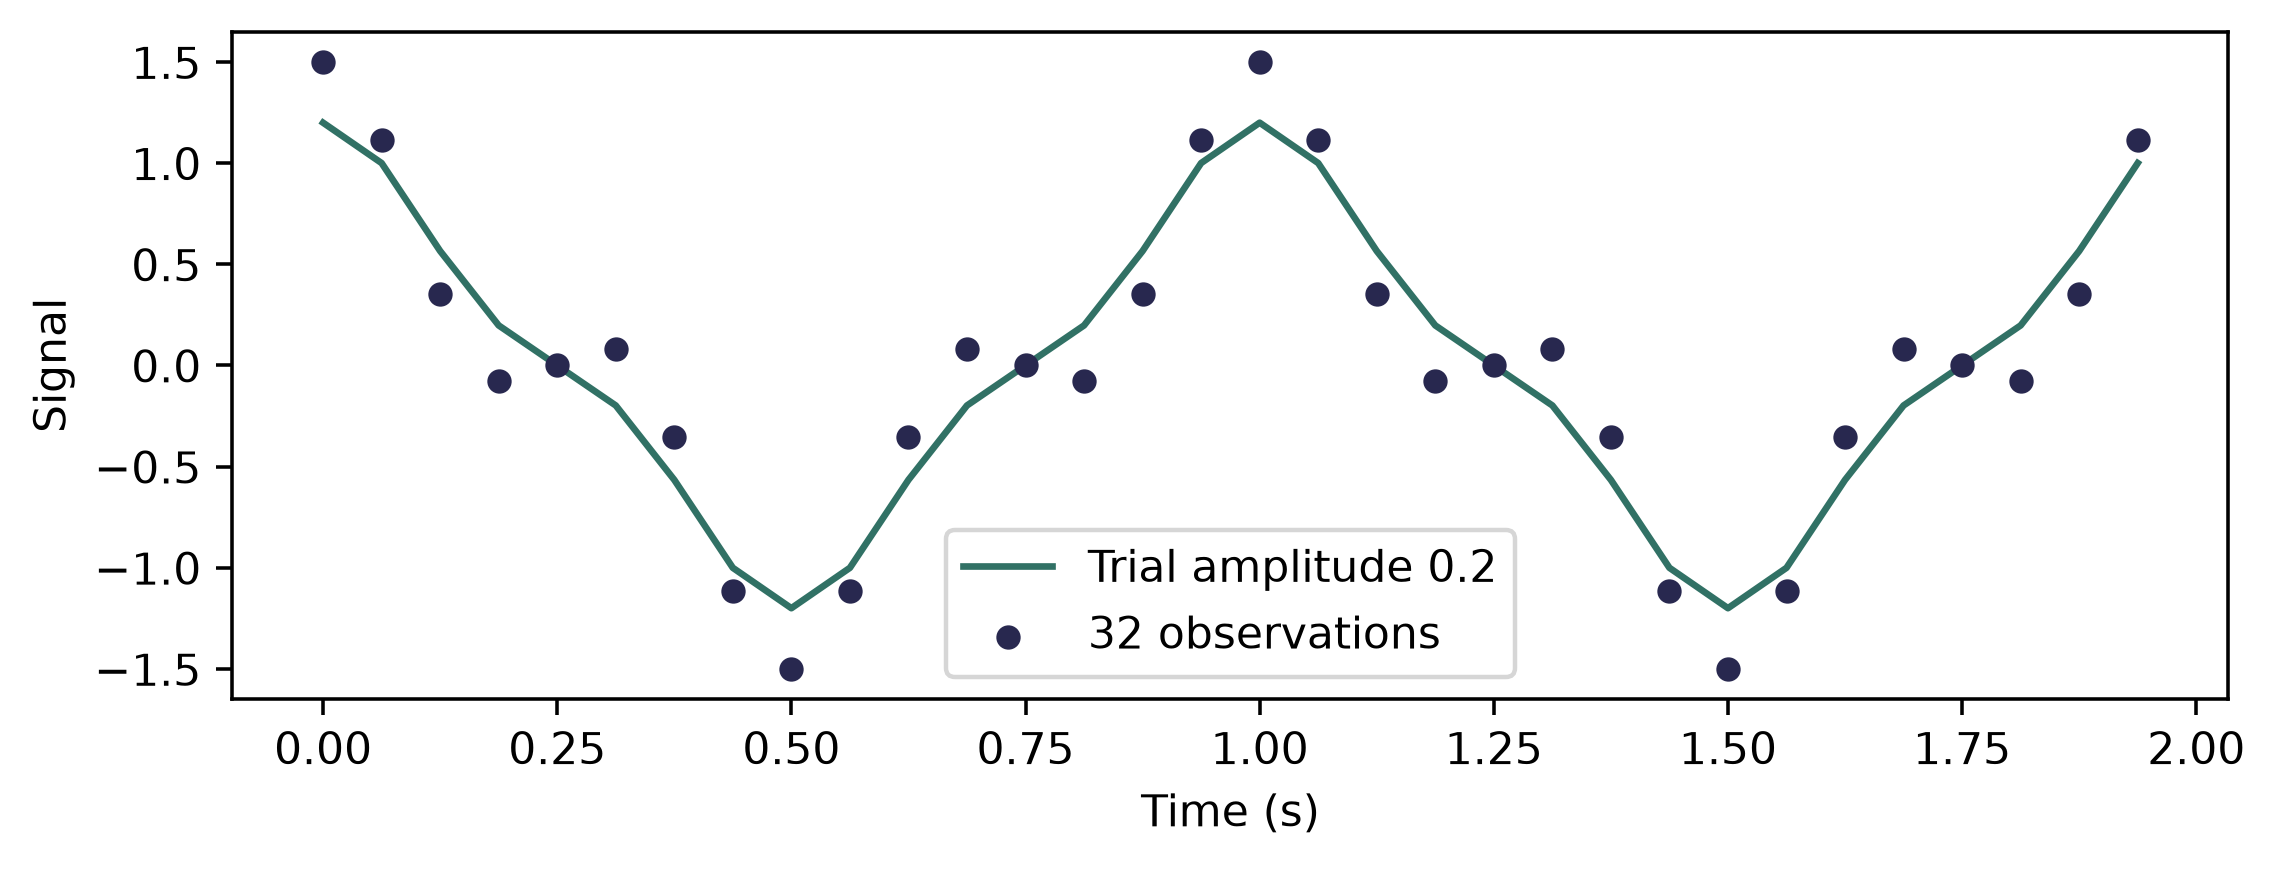

In [2]:
def predict(a, slow, ripple):
    return slow + a * ripple


def loss(a, slow, ripple, observed):
    residual = predict(a, slow, ripple) - observed
    return jnp.mean(residual**2)


trial = jnp.float32(0.2)
for a in (trial, jnp.float32(0.5)):
    print(f"a = {a:.1f}, loss = {loss(a, slow, ripple, observed):.3f}")

fig, ax = plt.subplots(figsize=(7, 2.6), layout="constrained")
ax.plot(t, predict(trial, slow, ripple), color="#317165", label="Trial amplitude 0.2")
ax.scatter(t, observed, s=20, color="#28284f", label="32 observations", zorder=3)
ax.set(xlabel="Time (s)", ylabel="Signal")
ax.legend()
plt.show()

## 2. What does tracing record?

Take one sample for which the slow wave is 1 and the unit ripple is 1. At amplitude 0.2, Python evaluates the expression in `predict` as $1+0.2\times1=1.2$. Suppose we want to use the same calculation later, with an amplitude we do not yet know. We can already specify the two instructions: multiply the amplitude by the ripple, then add the slow wave.

**Tracing** is how JAX obtains those instructions. It runs the Python function using stand-ins for its inputs, called **tracers**. Here each tracer describes a shape and a numerical type. When Python reaches `a * ripple`, JAX records a multiplication and returns a tracer for its result. The addition takes that result as an input.

We can print the recorded operations with `jax.make_jaxpr`.

In [3]:
print(jax.make_jaxpr(predict)(trial, slow, ripple))

{ lambda ; a:f32[] b:f32[32] c:f32[32]. let
    d:f32[32] = mul a c
    e:f32[32] = add b d
  in (e,) }


Read the output from top to bottom. `f32[]` denotes one floating-point number and `f32[32]` denotes 32 of them. The output of `mul` feeds into `add`, which produces the predicted wave of shape `(32,)`. The same instructions work for a different numerical amplitude. The printed representation is called a **jaxpr**.

## 3. What does JIT compile and reuse?

**Just-in-time compilation (JIT)** translates part of a program into executable code while the program runs. In L1, CPython translated a function into bytecode for the Python interpreter. Here the XLA compiler can translate the array operations in `predict` into instructions for the laptop CPU.

Writing `compiled = jax.jit(predict)` creates a callable. On its first call, JAX knows the shapes and dtypes of the arguments. It traces the multiplication and addition, compiles the calculation for the device, and runs it with the supplied amplitude. It saves the executable so that we can use it again.

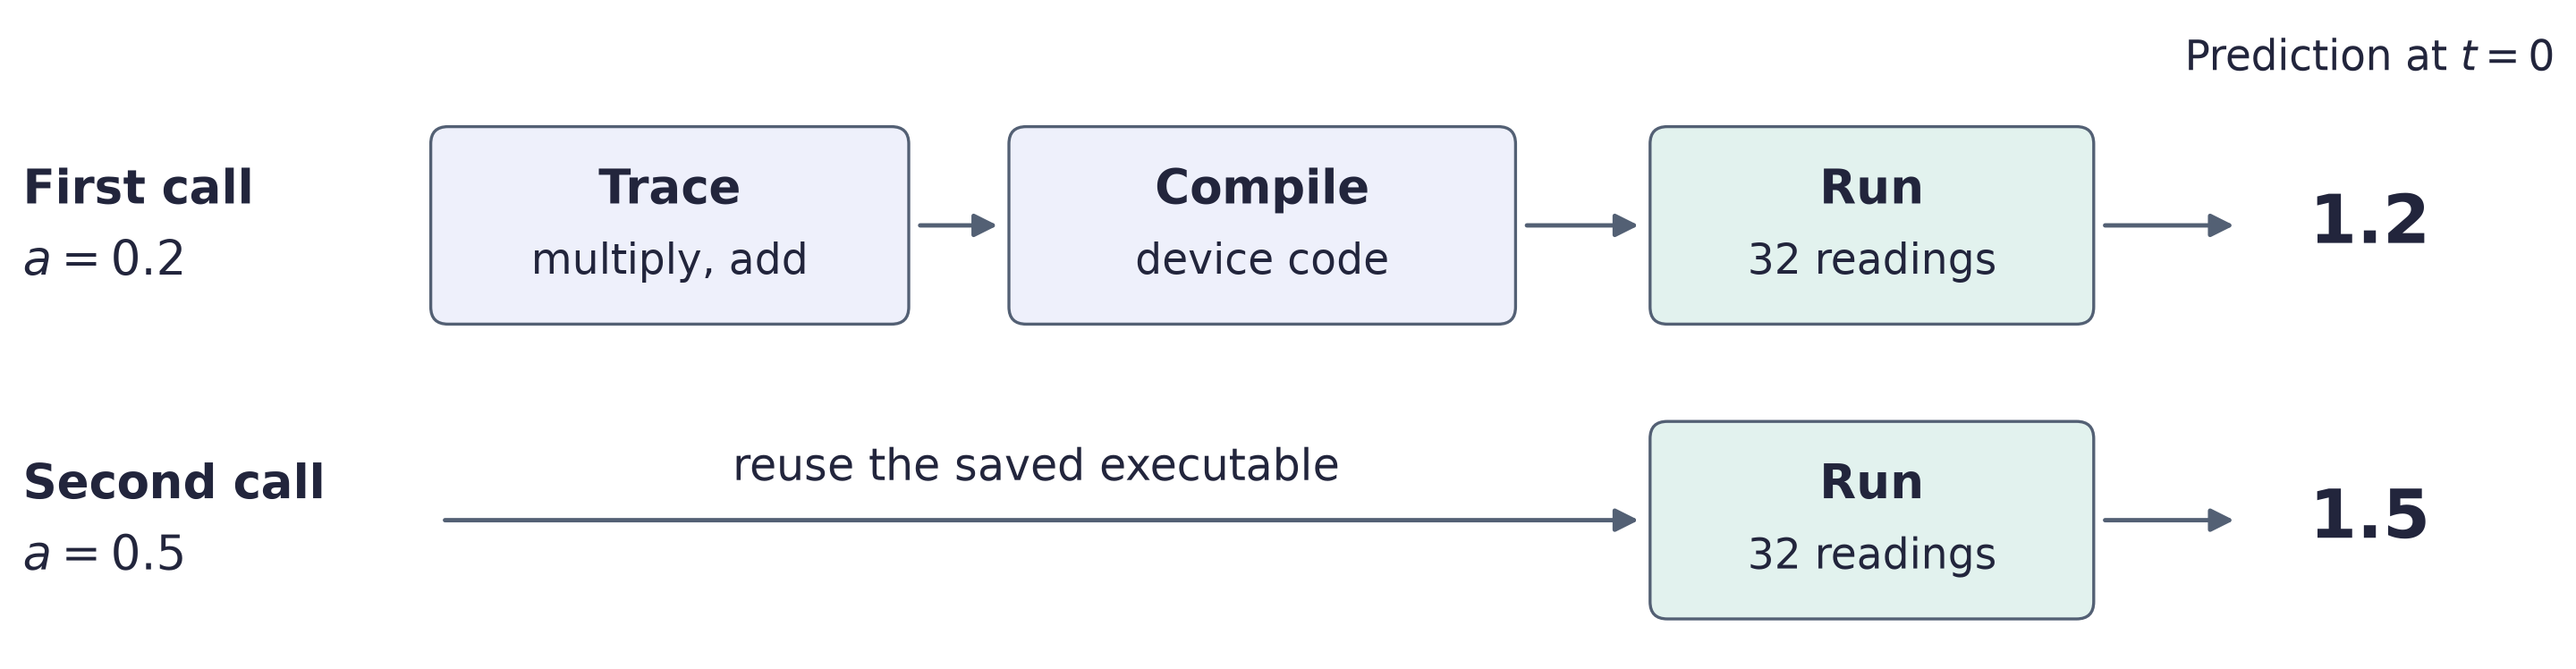

At time zero both waves equal 1. Changing the amplitude from 0.2 to 0.5 therefore changes the prediction even when JAX reuses the executable. Predict which of the four calls below will print “Tracing”. The ordinary Python `print` shows when Python runs the body.

In [4]:
@jax.jit
def compiled_prediction(a, slow, ripple):
    print(f"  Tracing for {slow.shape} and {slow.dtype}")
    return predict(a, slow, ripple)


for count, amplitude in [(32, 0.2), (32, 0.5), (16, 0.5), (32, 0.8)]:
    print(f"{count} readings, amplitude {amplitude}")
    wave = compiled_prediction(jnp.float32(amplitude), slow[:count], ripple[:count])
    print(f"  First prediction = {float(wave[0]):.1f}")

32 readings, amplitude 0.2
  Tracing for (32,) and float32
  First prediction = 1.2
32 readings, amplitude 0.5
  First prediction = 1.5
16 readings, amplitude 0.5
  Tracing for (16,) and float32


  First prediction = 1.5
32 readings, amplitude 0.8
  First prediction = 1.8


Calls 1 and 2 use the same shapes and types. The first prediction changes from 1.2 to 1.5 even though Python traces the function body only once for those inputs. Cutting the record to 16 readings produces a second trace. Call 4 returns to the original shape and reuses the first executable. Changing an input dtype can also require another executable.

The Python print was a diagnostic. In the fit itself, `predict` and `loss` are **pure functions**: their results depend on the arguments, and calling them leaves the surrounding program state unchanged.

### Why compile the whole prediction? \*

One way to compute `slow + a * ripple` is to write all 32 products to a temporary array, then read them back for the addition. A compiler that can see both operations may combine them into a single pass. This optimisation is called **fusion**.

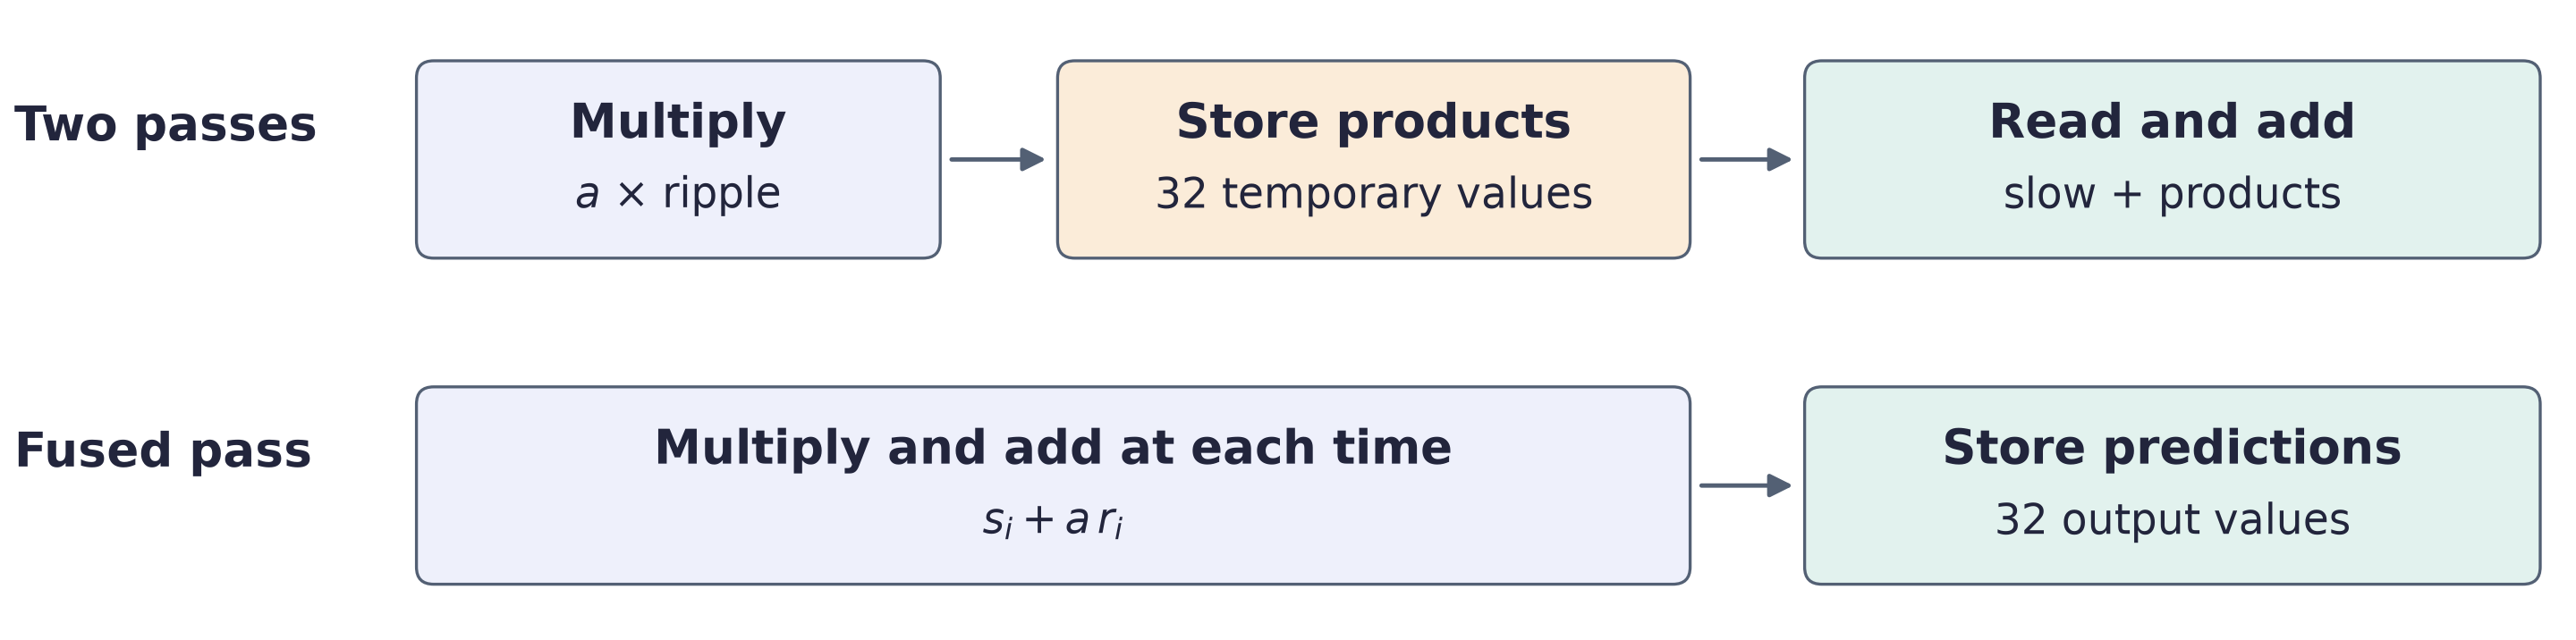

For the reading at half a second the two waves both equal $-1$. With $a=0.2$ we can multiply to get $-0.2$, add it immediately to $-1$, and store $-1.2$. The diagram shows one possible implementation. The precise instructions depend on the compiler and the device.

### A decision Python must make during tracing

Suppose we sometimes want to omit the ripple. We use a Python `if` to choose between the two predictions. What does JAX know about the flag during tracing?

- For a **dynamic argument**, JAX knows its shape and dtype during tracing. Its actual value is generally available only when the compiled code runs.
- For a **static argument**, JAX knows its actual value during tracing.

In the first call below, `a`, `slow`, `ripple` and `include_ripple` are all dynamic. JAX knows the flag is a scalar Boolean (shape `()`, dtype `bool`). Python needs to know whether it is `True` or `False` to choose a branch.

In [5]:
def choose_prediction(a, slow, ripple, include_ripple):
    if include_ripple:
        return predict(a, slow, ripple)
    return slow


try:
    jax.jit(choose_prediction)(trial, slow, ripple, True)
except jax.errors.TracerBoolConversionError as error:
    print(type(error).__name__)
    print(str(error).splitlines()[0])

choose = jax.jit(choose_prediction, static_argnames=("include_ripple",))
for flag in (True, False):
    prediction = choose(trial, slow, ripple, flag)
    print(f"include_ripple={flag}, first prediction = {prediction[0]:.1f}")

TracerBoolConversionError
Attempted boolean conversion of traced array with shape bool[].
include_ripple=True, first prediction = 1.2
include_ripple=False, first prediction = 1.0


In the version that names the flag in `static_argnames`:

- **Static:** `include_ripple`. Python uses its value during tracing to choose the ripple branch (`True`) or the slow wave alone (`False`). JAX compiles one version for each choice.
- **Dynamic:** `a`, `slow`, `ripple`. JAX can trace `slow + a * ripple` from their shapes and dtypes. Their values determine the predicted wave when the code runs.

A slice can raise a similar question. If a function returns the first $m$ residuals, the length of its result depends on $m$. With an ordinary slice inside `jit`, making $m$ static lets JAX determine that length when it traces the function.

In [6]:
def first_residuals(a, slow, ripple, observed, m):
    return (predict(a, slow, ripple) - observed)[:m]


first = jax.jit(first_residuals, static_argnames=("m",))
for m in (3, 5):
    print(f"m = {m}, output shape = {first(trial, slow, ripple, observed, m).shape}")

m = 3, output shape = (3,)
m = 5, output shape = (5,)


For `first_residuals`:

- **Static:** `m`. JAX uses its value during tracing to determine the output shape, just as Python used the static flag to choose a branch.
- **Dynamic:** `a`, `slow`, `ripple`, `observed`. Their shapes and dtypes suffice to trace the prediction and subtraction. The compiled code uses their values to calculate the residuals.

## 4. Which way should we change the amplitude? \*

At $a=0.2$ the loss was 0.045. Would increasing the amplitude improve the fit? For one reading, keep the waves and the observation fixed. The prediction, the residual and its square are

$$
\hat y_i=s_i+a r_i,\qquad e_i=\hat y_i-y_i,\qquad q_i=e_i^2.
$$

A change in the prediction passes straight through the subtraction because $y_i$ is fixed. The chain rule multiplies the rates for the three operations:

$$
\frac{\mathrm d q_i}{\mathrm d a}
=\underbrace{\frac{\mathrm d q_i}{\mathrm d e_i}}_{2e_i}
 \underbrace{\frac{\mathrm d e_i}{\mathrm d\hat y_i}}_{1}
 \underbrace{\frac{\mathrm d\hat y_i}{\mathrm d a}}_{r_i}
=2e_i r_i.
$$

At the first reading $e_0=1.2-1.5=-0.3$ and $r_0=1$, so its squared error has slope $-0.6$. The loss averages all 32 squared errors, giving

$$
L'(a)=\frac{1}{32}\sum_{i=0}^{31}2e_i(a)r_i .
$$

We can evaluate this expression ourselves and compare it with `jax.grad(loss)`, which differentiates with respect to the first argument, $a$. The central difference uses two nearby amplitudes as a separate numerical check.

In [7]:
slope = jax.grad(loss)(trial, slow, ripple, observed)
residuals = predict(trial, slow, ripple) - observed
reading_slopes = 2 * residuals * ripple
print(f"First squared-error slope: {reading_slopes[0]:.4f}")
print(f"Mean slope by the chain rule: {reading_slopes.mean():.4f}")
step = 0.001
above = loss(trial + step, slow, ripple, observed)
below = loss(trial - step, slow, ripple, observed)
print(f"Automatic derivative: {slope:.4f}")
print(f"Central difference:   {(above - below) / (2 * step):.4f}")
value, slope = jax.value_and_grad(loss)(trial, slow, ripple, observed)
print(f"Loss and slope at a = {trial:.1f}: {value:.3f}, {slope:.3f}")

First squared-error slope: -0.6000
Mean slope by the chain rule: -0.3000


Automatic derivative: -0.3000


Central difference:   -0.3000
Loss and slope at a = 0.2: 0.045, -0.300


With $h=0.001$, both methods give the same slope to four decimal places. [Decrease the step size in the animation](https://teaching.borisbolliet.io/c1-2026/animations/class23-derivatives.html) and watch the two loss values. Once they round to the same number, their difference is zero.

The negative slope at $a=0.2$ means that increasing $a$ a little reduces the loss. To see where it reaches its minimum, we can plot the loss for a range of amplitudes. We already have the calculation for one amplitude. How do we apply it to several?

## 5. From one amplitude to a batch with vmap \*

Start with three amplitudes. For the first score we pass 0.2 and all 32 readings to `loss`. For the second we replace 0.2 with 0.5 and use the same readings again. A Python loop spells out which input varies.

In [8]:
amplitudes = jnp.array([0.2, 0.5, 0.8], dtype=jnp.float32)
loop_scores = jnp.stack([loss(a, slow, ripple, observed) for a in amplitudes])
print("Scores from the loop:", np.round(loop_scores, 3))

Scores from the loop: [0.045 0.    0.045]


`jax.vmap` (**vectorising map**) constructs a function that applies a single-example calculation across a chosen array axis. Here we want `scores[i]` to equal `loss(amplitudes[i], slow, ripple, observed)`. The four entries of `in_axes` correspond, in order, to the four arguments of `loss`.

| Argument | What one fit receives | Entry in `in_axes` |
|---|---|---|
| `amplitudes`, shape `(3,)` | One scalar, taken along axis 0 | `0` |
| `slow`, `ripple`, `observed`, each of shape `(32,)` | The same three complete time series for every fit | `None, None, None` |

We can see the two axes by first mapping `predict`. Each row of its output is a complete predicted wave for one amplitude. Column 0 contains the three predictions at time zero. At that time both cosines equal 1, so the predictions are $1+0.2$, $1+0.5$ and $1+0.8$.

In [9]:
predict_many = jax.vmap(predict, in_axes=(0, None, None))
waves = predict_many(amplitudes, slow, ripple)
print("Predicted waves (amplitude, time):", waves.shape)
print("Predictions at time zero:", np.asarray(waves[:, 0]))

Predicted waves (amplitude, time): (3, 32)
Predictions at time zero: [1.2 1.5 1.8]


Mapping `loss` gives a different output shape. Each call for a single amplitude compares one row of predictions with the 32 observations and averages the squared residuals over time. We therefore get one score per amplitude. JAX batches the array operations that compute these scores. The loop above gives us a way to check the result.

In [10]:
score_many = jax.vmap(loss, in_axes=(0, None, None, None))
scores = score_many(amplitudes, slow, ripple, observed)
print("Amplitude   Loss")
for a, score in zip(amplitudes, scores):
    print(f"{a:9.1f}   {score:.3f}")
print("Output shape:", scores.shape)
np.testing.assert_allclose(scores, loop_scores, atol=1e-6)

Amplitude   Loss
      0.2   0.045
      0.5   0.000
      0.8   0.045
Output shape: (3,)


Both 0.2 and 0.8 give a loss of 0.045. Each is 0.3 away from the amplitude that generated the readings. We can now pass 101 trial amplitudes to the same mapped function to draw the curve. Applying `jit` to `score_many` compiles that batched calculation. The number of amplitudes is a batch size, independent of the number of time samples or available devices.

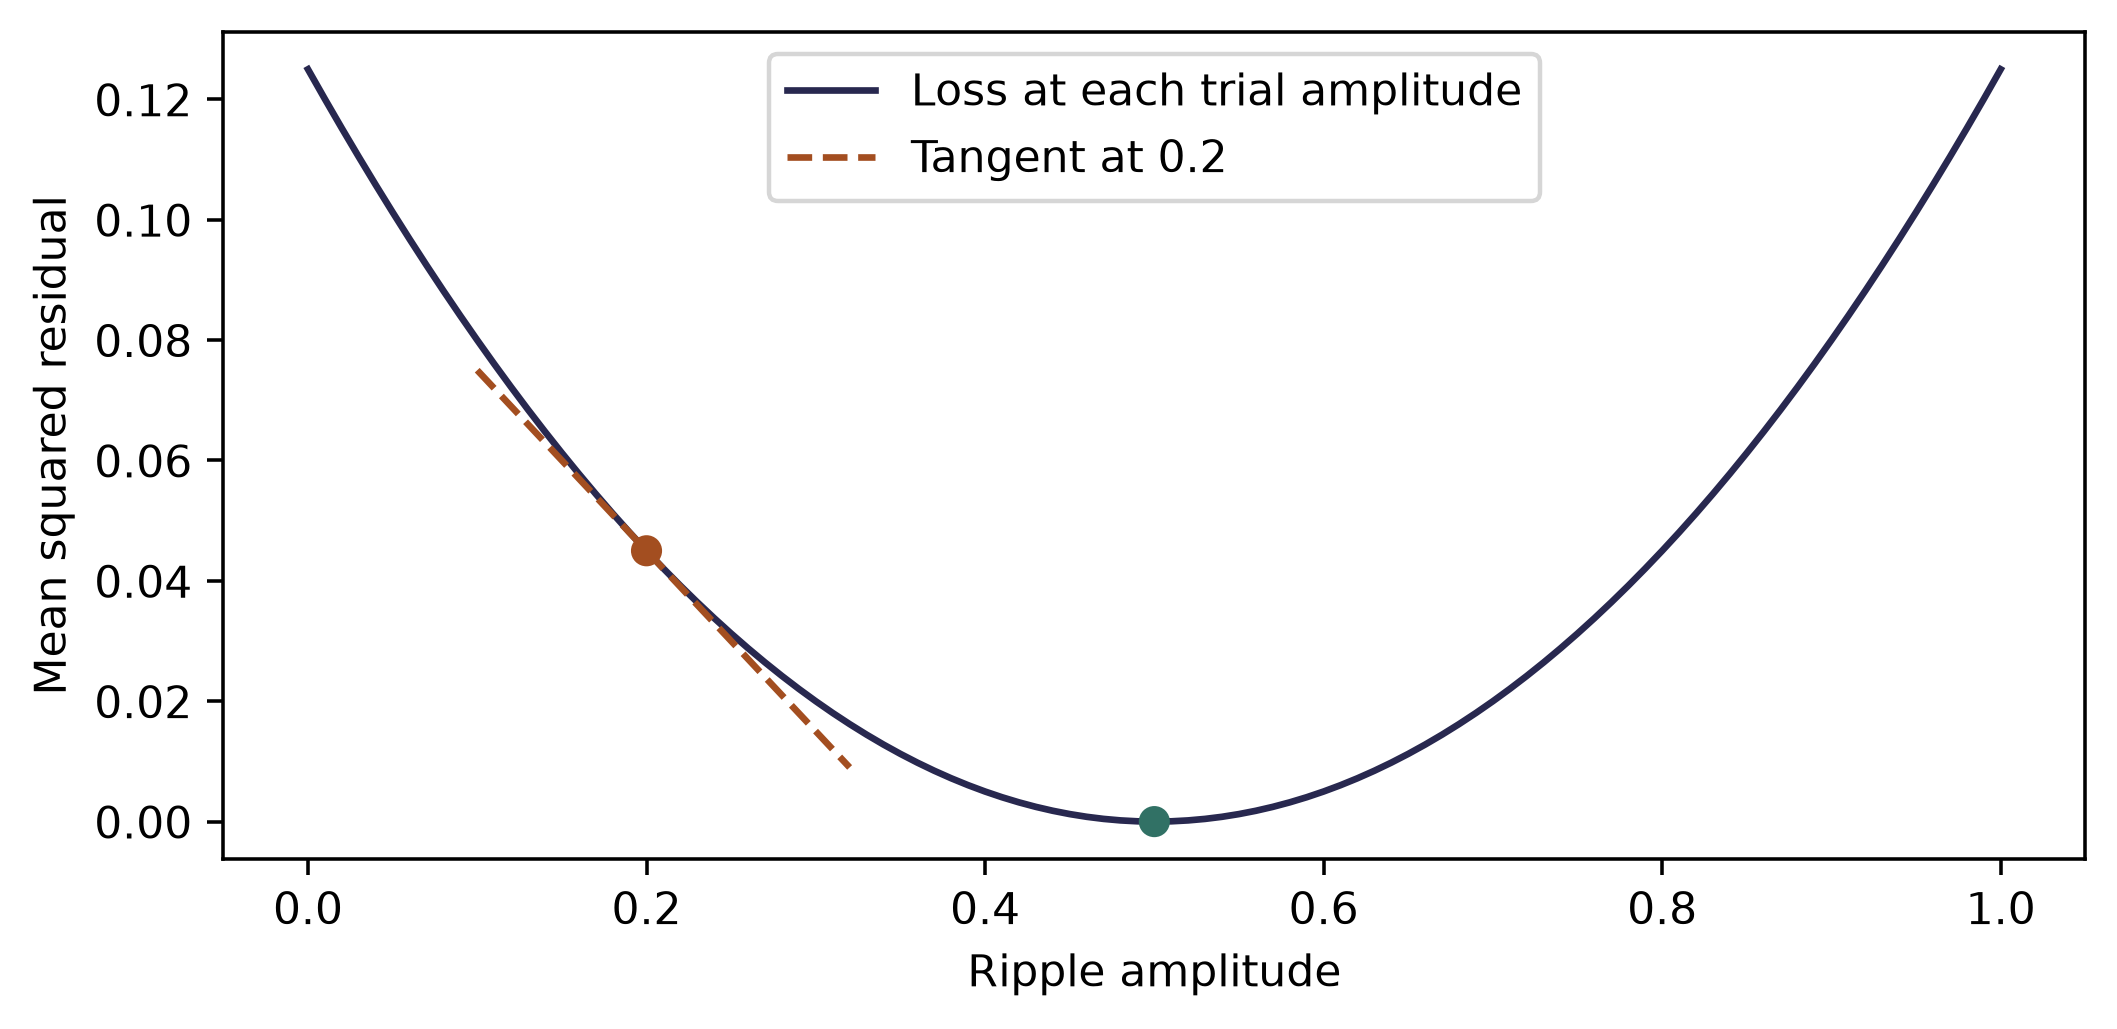

In [11]:
grid = jnp.linspace(0.0, 1.0, 101)
curve = jax.jit(score_many)(grid, slow, ripple, observed)
near_trial = np.linspace(0.10, 0.32)
fig, ax = plt.subplots(figsize=(6.5, 3.1), layout="constrained")
ax.plot(grid, curve, color="#28284f", label="Loss at each trial amplitude")
ax.plot(near_trial, float(value) + float(slope) * (near_trial - float(trial)),
        "--", color="#a34e20", label="Tangent at 0.2")
ax.scatter([float(trial), 0.5], [float(value), 0], color=["#a34e20", "#317165"], zorder=3)
ax.set(xlabel="Ripple amplitude", ylabel="Mean squared residual")
ax.legend()
plt.show()

## 6. Dispatch and benchmarking

### When does Python wait?

**Dispatch** means submitting work to a device. With synchronous dispatch, Python waits for each result before the call returns. With [asynchronous dispatch](https://docs.jax.dev/en/latest/async_dispatch.html), Python can receive a JAX array whose numerical values are still being computed. It can pass that array to the next JAX operation. The device respects the dependency between the two operations.

![Two schedules on a single GPU. With a wait after each submission Python and the GPU take turns. With asynchronous dispatch Python can queue all three calls, prepare a label, then wait for the score. The GPU still computes prediction, residual and mean square in order.](attachment:dispatch.png)

Here we split the ripple loss into the three separate calls shown in the figure. The numbered blocks indicate when Python submits each call. Block widths illustrate the order of events. On a CPU or for a small array a calculation may already be complete when Python gets the array back.
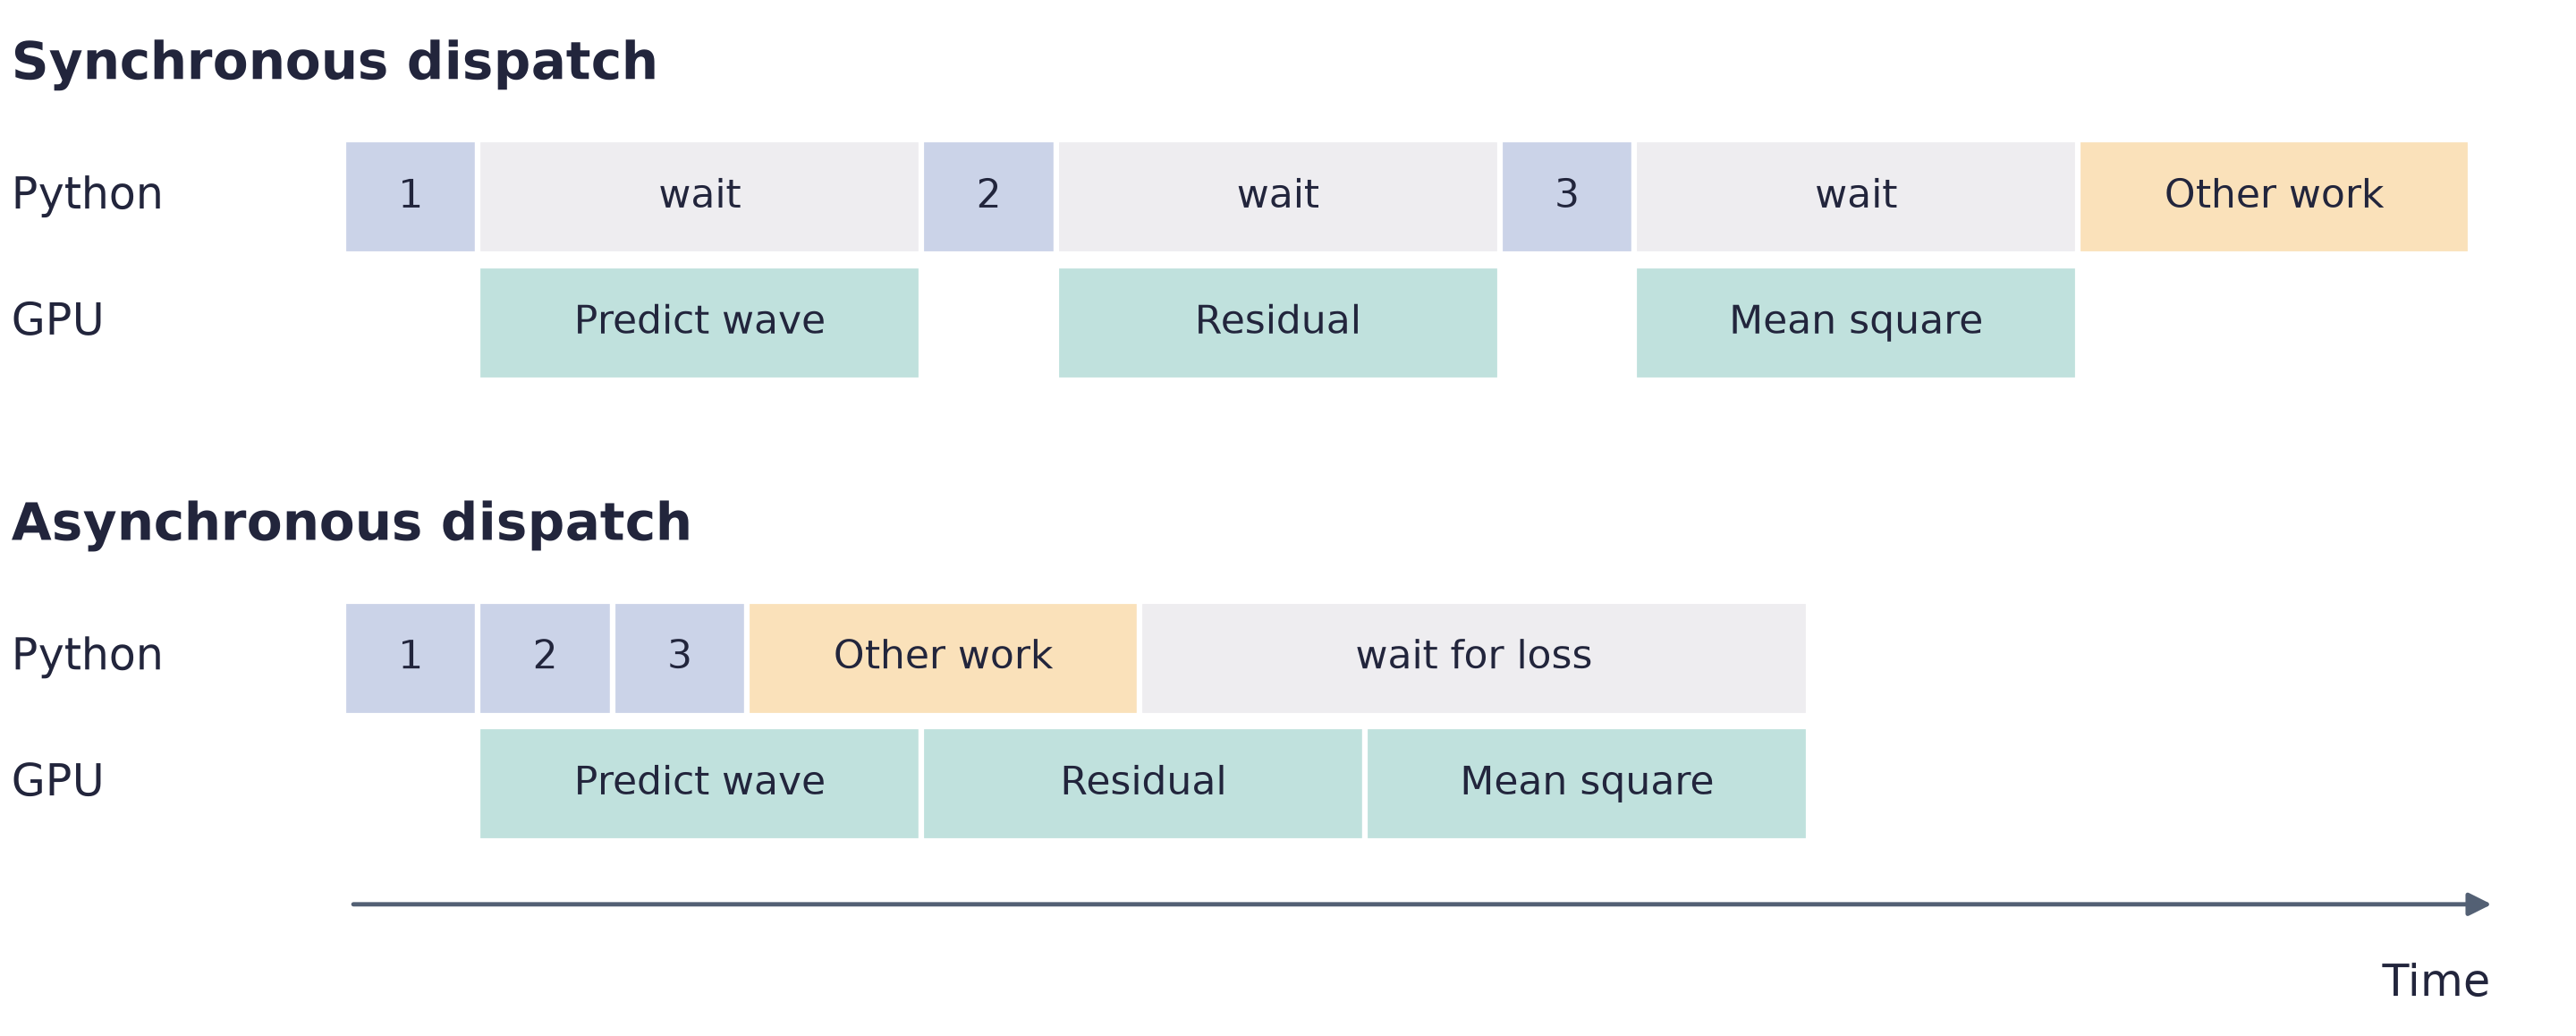

In [12]:
mean_square = jax.jit(lambda e: jnp.mean(e**2))
wave = compiled_prediction(trial, slow, ripple)  # 1
residual = jnp.subtract(wave, observed)          # 2
score = mean_square(residual)                    # 3
label = "Ripple fit at a = 0.2"
score.block_until_ready()
print(f"{label}: {float(score):.3f}")

Ripple fit at a = 0.2: 0.045


Python can prepare the label without knowing the score. A call to `float(score)` needs the numerical value, so it would also wait if that value were still pending. To impose the upper schedule, add `.block_until_ready()` to the end of each of the three numbered expressions.

### Benchmarking a matrix product

In L18 each column of $\Omega$ was a trial vector. We benchmark the product $A\Omega$ with all 20 columns. We generate both input arrays on the device and wait until they are ready before starting the timer.

**First-call latency** measures how long we wait for the first result. If JAX has no executable cached for the function and these input types and shapes, that time includes tracing, compilation and the multiplication. The first call also serves as the **warm-up** for the seven **warm calls** that reuse the executable. Only those seven timings enter the median.

In [13]:
A = jax.random.normal(jax.random.key(1), (4096, 4096), dtype=jnp.float32)
omega = jax.random.normal(jax.random.key(2), (4096, 20), dtype=jnp.float32)
jax.block_until_ready((A, omega))
product = jax.jit(lambda matrix, vectors: matrix @ vectors)


def time_product():
    start = perf_counter()
    product(A, omega).block_until_ready()
    return 1000 * (perf_counter() - start)


print(A.device, A.shape, omega.shape, A.dtype)
print(f"First-call latency: {time_product():.2f} ms")
times = [time_product() for _ in range(7)]
print(f"Median of seven warm calls: {median(times):.2f} ms")

# Record two timestamps for the same warm call.
start = perf_counter()
result = product(A, omega)
returned = perf_counter()
result.block_until_ready()
finished = perf_counter()
print(f"Until Python gets the array: {1000 * (returned - start):.3f} ms")
print(f"Until the product is ready:  {1000 * (finished - start):.3f} ms")

cpu:0 (4096, 4096) (4096, 20) float32
First-call latency: 4.87 ms
Median of seven warm calls: 0.84 ms
Until Python gets the array: 0.051 ms
Until the product is ready:  0.875 ms


Both final timings start at the same instant. The first includes submission and any computation completed before Python gets the array. Only the second guarantees that the whole multiplication has finished. The two can be close when the result is already ready. The median gives the middle of seven warm measurements and is less sensitive to an occasional long call. Save the device, shapes and dtype with the timings for the L24 comparison.

In the [DIS JAX-on-TPU workshop notebook](https://github.com/MilesCranmer/dis-2026-jax-tpu-workshop/blob/main/notebooks/dis_2026_jax_tpu_gpt2_shakespeare.ipynb), §1 times a matrix product on the TPU. In the optional training example in §7, the model has many trainable weights. Each training step computes a loss and its gradients with respect to those weights, just as our fit computed a loss and its slope with respect to one amplitude.

[Tracing](https://docs.jax.dev/en/latest/tracing.html) · [Just-in-time compilation](https://docs.jax.dev/en/latest/jit-compilation.html) · [Automatic differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html) · [Automatic vectorisation](https://docs.jax.dev/en/latest/automatic-vectorization.html)